# Predicción de la volatilidad de la cartera

Modelos ARCH(p), GARCH(1,1) y GJR-GARCH(1,1) para Caterpillar (CAT), Merck (MRK) y Microsoft (MSFT). Se comparan por su ajuste (log-verosimilitud, AIC, BIC) y por su predicción en un periodo de test frente a la volatilidad realizada y a tres predicciones de referencia (RMSE y MAE).

- **Entrada:** `Datos/Transformados/dowjones_diario_2016_2025.csv` (precio de cierre diario)
- **Salida:** gráficos en `Graficos/` y `Datos/Transformados/volatilidad_errores.csv`

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from arch import arch_model
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

#Estilo común de los gráficos 
RAIZ_PROYECTO = next((d for d in [Path.cwd(), *Path.cwd().parents] if (d / "packages" / "bbva_graficos.py").exists()), None)
if RAIZ_PROYECTO is None:
    raise FileNotFoundError(f"No se encuentra packages/bbva_graficos.py ni en {Path.cwd()} ni en sus carpetas superiores. "
                            "Copia la carpeta packages/ en la raíz del proyecto.")
sys.path.insert(0, str(RAIZ_PROYECTO))
from packages.bbva_graficos import BBVA, cerrar_grafico, configurar_graficos, fmt_es
configurar_graficos()

PosixPath('Graficos')

In [2]:
#Rutas y parámetros comunes
RUTA_DATOS = RAIZ_PROYECTO / "Datos" / "Transformados" / "dowjones_diario_2016_2025.csv"
RUTA_RESULTADOS = RAIZ_PROYECTO / "Datos" / "Transformados"

ACTIVOS = {"CAT": "Caterpillar", "MRK": "Merck", "MSFT": "Microsoft"}
DIAS_ANIO = 252             # sesiones por año, para anualizar

#Colores de la paleta BBVA
PRINCIPAL, CIELO, AGUAMARINA, MARINO = (BBVA[k] for k in ("principal", "cielo", "agua", "marino"))
GRIS = BBVA["gris_dato"]          # en bbva_graficos.py, "gris" es el de fondo y "gris_dato" el de las series
GRIS_FONDO = BBVA["gris"]
FUENTE = "elaboración propia a partir de los cierres diarios del Dow Jones (2016-2025)."
pd.set_option("display.width", 200)


def eje_porcentaje(ax, decimales=0):
    # Eje Y con valores que ya están en porcentaje (25 -> "25 %")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{fmt_es(v, decimales)} %"))


def eje_anios(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


## 1. Datos

Rentabilidad logarítmica diaria en % (multiplicada por 100 para que `arch` estime mejor). Train: 2016-2023. Test: 2024-2025.

In [3]:
#Parámetros de esta sección
INICIO_TEST = "2024-01-01"  #Train: 2016-2023 y Test: 2024-2025

df = pd.read_csv(RUTA_DATOS, parse_dates=["date"])
precios = df[df["symbol"].isin(ACTIVOS)].pivot(index="date", columns="symbol", values="close")[list(ACTIVOS)].sort_index()
rent = 100 * np.log(precios).diff().dropna()          # rentabilidad logarítmica diaria, en %

en_test = rent.index >= INICIO_TEST
N_TRAIN = int((~en_test).sum())
print(f"Rentabilidades diarias: {len(rent)} | entrenamiento: {N_TRAIN} sesiones "
      f"({rent.index[0].date()} a {rent.index[N_TRAIN - 1].date()}) | test: {int(en_test.sum())} sesiones "
      f"({rent.index[N_TRAIN].date()} a {rent.index[-1].date()})")

resumen = pd.DataFrame({
    "media_diaria_%": rent[~en_test].mean(),
    "vol_anual_entrenamiento_%": rent[~en_test].std() * np.sqrt(DIAS_ANIO),
    "vol_anual_test_%": rent[en_test].std() * np.sqrt(DIAS_ANIO),
    "curtosis_exceso": rent[~en_test].kurt(),
    "peor_dia_%": rent.min(),
    "mejor_dia_%": rent.max(),
})
print(resumen.round(2).to_string())

Rentabilidades diarias: 2513 | entrenamiento: 2011 sesiones (2016-01-05 a 2023-12-29) | test: 502 sesiones (2024-01-02 a 2025-12-31)
        media_diaria_%  vol_anual_entrenamiento_%  vol_anual_test_%  curtosis_exceso  peor_dia_%  mejor_dia_%
symbol                                                                                                       
CAT               0.07                      30.80             29.01             4.68      -15.34        11.01
MRK               0.04                      21.67             26.29             7.67      -10.38         9.90
MSFT              0.10                      27.80             22.10             7.73      -15.95        13.29


Guardado: Graficos/volatilidad_01_rentabilidad_diaria.png


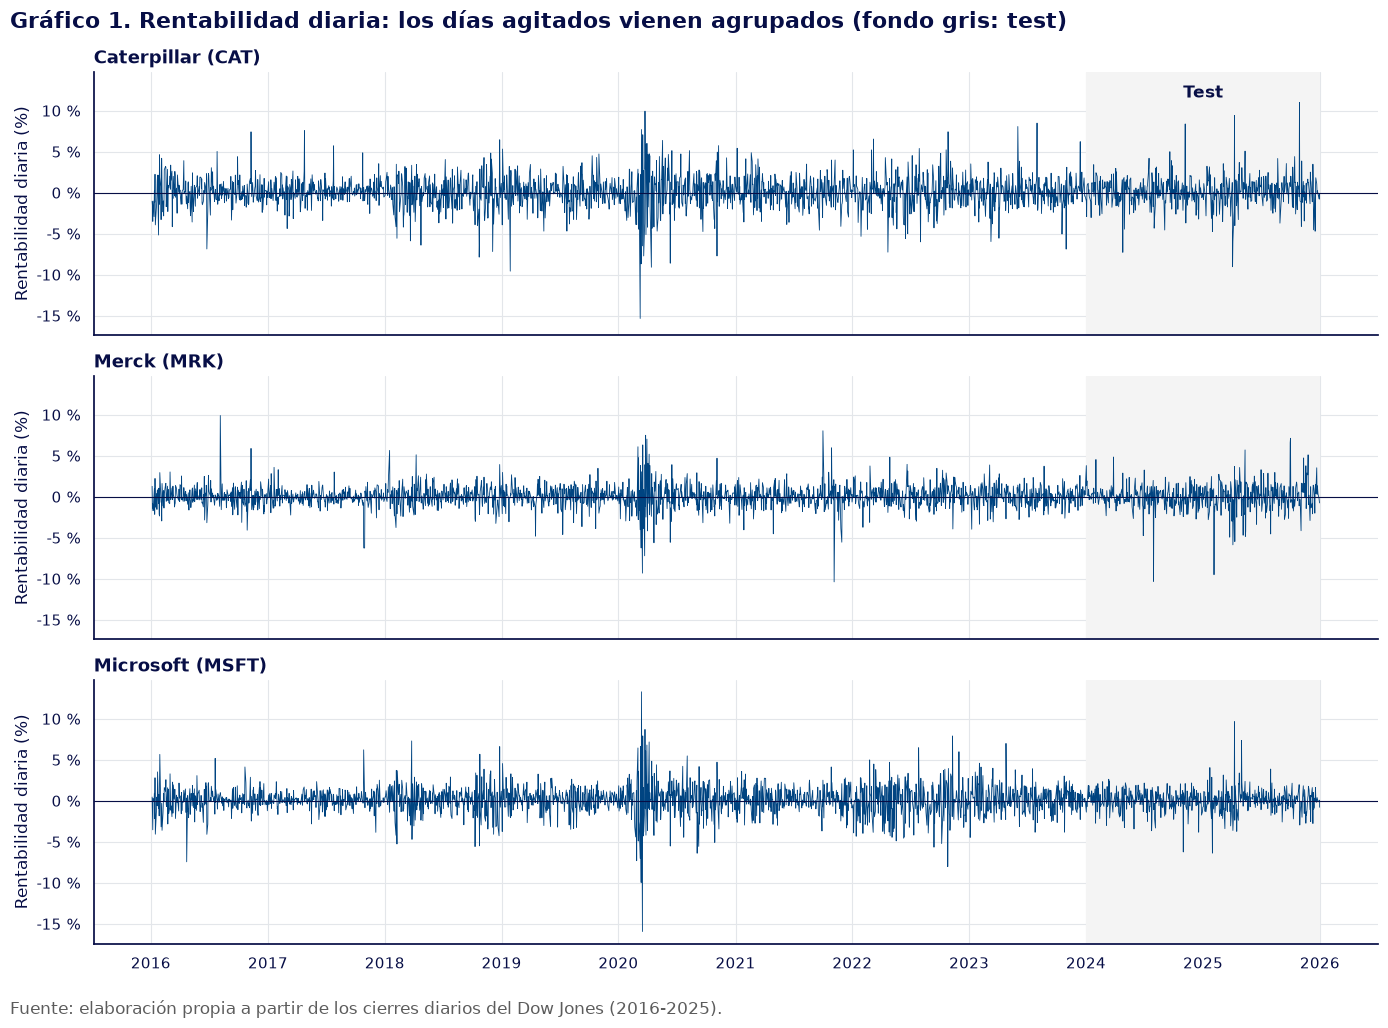

PosixPath('Graficos/volatilidad_01_rentabilidad_diaria.png')

In [4]:
fig, ejes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, sharey=True)
for ax, t in zip(ejes, ACTIVOS):
    ax.axvspan(pd.Timestamp(INICIO_TEST), rent.index[-1], color=GRIS_FONDO, lw=0)
    ax.plot(rent[t], color=PRINCIPAL, lw=0.6)
    ax.axhline(0, color=MARINO, lw=0.8)
    eje_porcentaje(ax)
    ax.set_ylabel("Rentabilidad diaria (%)")
    ax.set_title(f"{ACTIVOS[t]} ({t})")
ejes[0].text(pd.Timestamp("2025-01-01"), 0.95, "Test", transform=ejes[0].get_xaxis_transform(),
             ha="center", va="top", color=MARINO, fontsize=12, fontweight="bold")
eje_anios(ejes[-1])
fig.suptitle("Gráfico 1. Rentabilidad diaria: los días agitados vienen agrupados (fondo gris: test)",
             x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "volatilidad_01_rentabilidad_diaria", fuente=FUENTE)

ANÁLISIS:

Hay 2.011 sesiones de entrenamiento y 502 de test. Los días de grandes movimientos aparecen agrupados (2020, 2022, abril de 2025) y hay caídas de hasta −16 % en un día (curtosis de 4,7 a 7,8: colas más gruesas que una normal). En el test, Merck fue más volátil que en el entrenamiento (26,3 % anual frente a 21,7 %), Microsoft menos (22,1 % frente a 27,8 %) y Caterpillar parecido (29,0 % frente a 30,8 %).

## 2. Agrupamiento de la volatilidad y elección de p

Test de Ljung-Box sobre la rentabilidad y sobre la rentabilidad al cuadrado. Como indica el tema, los retardos de los modelos de volatilidad se eligen con la PACF de la rentabilidad al cuadrado; para el ARCH(p) se toma el p con menor BIC entre 1 y 10.

In [5]:
#Parámetros de esta sección
RETARDOS_LB = 10            #Retardos del test de Ljung-Box


def ljung_box(serie, retardos):
    #Test de Ljung-Box: sigue una chi-cuadrado con `retardos` grados de libertad si la serie no tiene autocorrelación. 
    x = np.asarray(serie, dtype=float)
    x = x - x.mean()
    n = len(x)
    rho = np.array([np.sum(x[k:] * x[:-k]) / np.sum(x * x) for k in range(1, retardos + 1)])
    q = n * (n + 2) * np.sum(rho ** 2 / (n - np.arange(1, retardos + 1)))
    return q, stats.chi2.sf(q, retardos)


filas = {}
for t in ACTIVOS:
    r = rent[t][~en_test]
    q_r, p_r = ljung_box(r, RETARDOS_LB)
    q_r2, p_r2 = ljung_box(r ** 2, RETARDOS_LB)
    filas[t] = {"LB_rentabilidad_Q": q_r, "LB_rentabilidad_p": p_r, "LB_rent_cuadrado_Q": q_r2, "LB_rent_cuadrado_p": p_r2}
agrupamiento = pd.DataFrame(filas).T
print(f"Test de Ljung-Box con {RETARDOS_LB} retardos, periodo de entrenamiento:")
print(agrupamiento.round(4).to_string())

Test de Ljung-Box con 10 retardos, periodo de entrenamiento:
      LB_rentabilidad_Q  LB_rentabilidad_p  LB_rent_cuadrado_Q  LB_rent_cuadrado_p
CAT             36.0747             0.0001            415.3373                 0.0
MRK             87.2499             0.0000            418.0760                 0.0
MSFT           158.7321             0.0000           1305.0584                 0.0


Guardado: Graficos/volatilidad_02_pacf_cuadrado.png


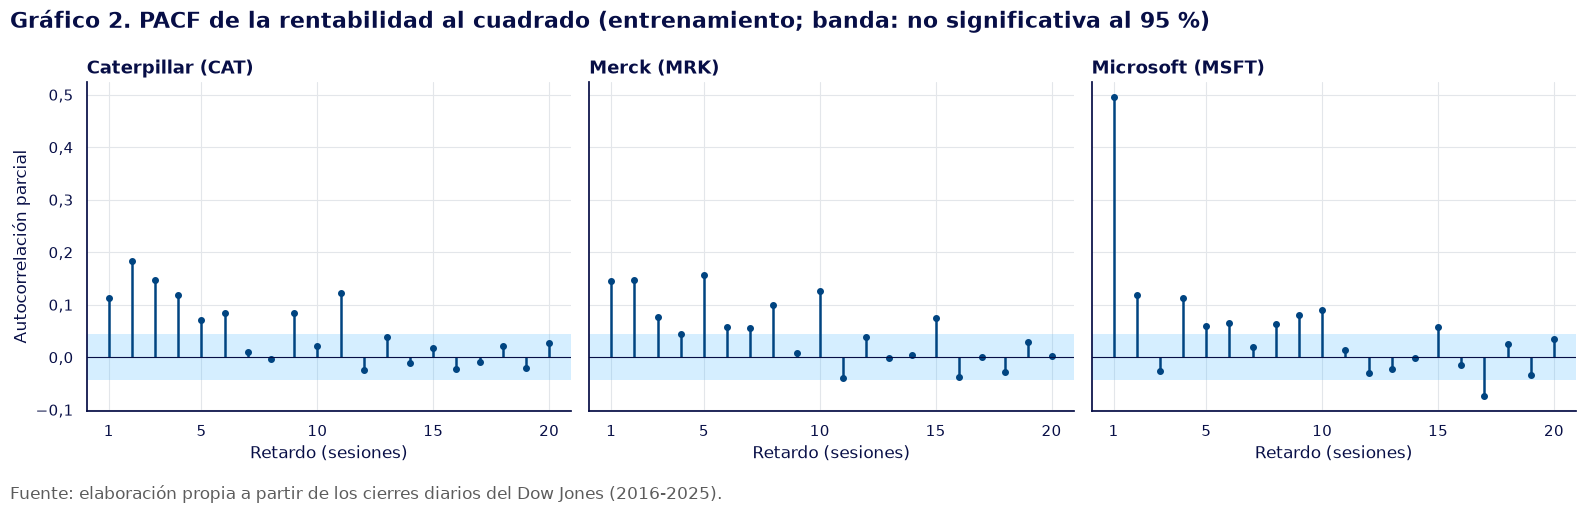

BIC de los ARCH(p) (entrenamiento):
       CAT     MRK    MSFT
1   8307.1  6863.0  7674.9
2   8225.4  6789.6  7586.8
3   8218.9  6791.0  7558.1
4   8198.1  6795.5  7535.1
5   8201.3  6775.8  7501.0
6   8207.6  6751.6  7505.4
7   8214.9  6753.6  7497.5
8   8221.9  6760.1  7505.1
9   8228.1  6767.7  7512.2
10  8227.4  6772.5  7514.7

p elegido por el BIC: {'CAT': 4, 'MRK': 6, 'MSFT': 7}


In [6]:
#Parámetros de esta sección
RETARDOS_PACF = 20          #Retardos de la PACF de la rentabilidad al cuadrado
P_MAX_ARCH = 10           


def pacf_yw(serie, retardos):
    #PACF por Yule-Walker: el coeficiente de orden k de un AR(k) ajustado con las autocorrelaciones
    x = np.asarray(serie, dtype=float) - np.mean(serie)
    rho = np.array([1.0] + [np.sum(x[k:] * x[:-k]) / np.sum(x * x) for k in range(1, retardos + 1)])
    resultado = []
    for k in range(1, retardos + 1):
        R = np.array([[rho[abs(i - j)] for j in range(k)] for i in range(k)])
        resultado.append(np.linalg.solve(R, rho[1:k + 1])[-1])
    return np.array(resultado)


fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
banda = 1.96 / np.sqrt(N_TRAIN)
for ax, t in zip(ejes, ACTIVOS):
    valores = pacf_yw(rent[t].iloc[:N_TRAIN] ** 2, RETARDOS_PACF)
    retardos = np.arange(1, RETARDOS_PACF + 1)
    ax.axhspan(-banda, banda, color=CIELO, alpha=0.25, lw=0)
    ax.vlines(retardos, 0, valores, color=PRINCIPAL, lw=1.8)
    ax.plot(retardos, valores, "o", ms=4, color=PRINCIPAL)
    ax.axhline(0, color=MARINO, lw=0.8)
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.set_xlabel("Retardo (sesiones)")
    ax.set_title(f"{ACTIVOS[t]} ({t})")
ejes[0].set_ylabel("Autocorrelación parcial")
fig.suptitle("Gráfico 2. PACF de la rentabilidad al cuadrado (entrenamiento; banda: no significativa al 95 %)",
             x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "volatilidad_02_pacf_cuadrado", fuente=FUENTE)

#BIC de los ARCH(p) con p = 1..P_MAX_ARCH, ajustados con el train
bic_arch = pd.DataFrame({t: {p: arch_model(rent[t], mean="Constant", vol="ARCH", p=p, dist="normal")
                                .fit(last_obs=N_TRAIN, disp="off").bic
                             for p in range(1, P_MAX_ARCH + 1)} for t in ACTIVOS})
P_ARCH = bic_arch.idxmin().to_dict()
print("BIC de los ARCH(p) (entrenamiento):")
print(bic_arch.round(1).to_string())
print("\np elegido por el BIC:", P_ARCH)

ANÁLISIS:

La rentabilidad al cuadrado está muy autocorrelacionada en los tres activos (Q = 415, 419 y 1.303; p < 0,001): los movimientos grandes se agrupan, así que tiene sentido usar modelos ARCH/GARCH. La rentabilidad sin elevar al cuadrado también es significativa, pero mucho menos (Q entre 37 y 163), por eso la media se modeliza como una constante.

En la PACF de la rentabilidad al cuadrado hay muchos retardos significativos (en Caterpillar del 1 al 6, el 9 y el 11; en Merck hasta el 10 y el 15), así que un ARCH necesita muchos retardos: el BIC elige p = 4 en Caterpillar, 6 en Merck y 7 en Microsoft. El GARCH(1,1) recoge esa memoria larga con solo un parámetro más (β).

## 3. Modelos de volatilidad

- **ARCH(p):** $\sigma^2_t = \omega + \sum_{i=1}^{p} \alpha_i\,\varepsilon^2_{t-i}$, con el p de la sección 2.
- **GARCH(1,1):** $\sigma^2_t = \omega + \alpha\,\varepsilon^2_{t-1} + \beta\,\sigma^2_{t-1}$. α mide la reacción a la sorpresa del día y β la memoria de la volatilidad.
- **GJR-GARCH(1,1)-t:** añade $\gamma\,\varepsilon^2_{t-1}\,I(\varepsilon_{t-1}<0)$, que permite que las caídas aumenten la volatilidad más que las subidas, y usa una distribución t de Student para recoger las colas gruesas.

Media constante en los tres y ajuste solo con el entrenamiento. Se comparan con la log-verosimilitud, el AIC, el BIC y el test de Ljung-Box sobre la rentabilidad estandarizada al cuadrado (si p > 0,05, el modelo recoge el agrupamiento).

In [7]:
def especificaciones(t):
    return {
        f"ARCH({P_ARCH[t]})": dict(vol="ARCH", p=P_ARCH[t], dist="normal"),
        "GARCH(1,1)": dict(vol="GARCH", p=1, q=1, dist="normal"),
        "GJR-GARCH(1,1)-t": dict(vol="GARCH", p=1, o=1, q=1, dist="t"),
    }


def persistencia(params):
    alfas = params.filter(like="alpha").sum()
    gammas = params.filter(like="gamma").sum()
    betas = params.filter(like="beta").sum()
    return alfas + 0.5 * gammas + betas


ajustes, comparacion = {}, []
for t in ACTIVOS:
    for nombre, kw in especificaciones(t).items():
        res = arch_model(rent[t], mean="Constant", **kw).fit(last_obs=N_TRAIN, disp="off")
        ajustes[(t, nombre)] = res
        pers = persistencia(res.params)
        z = res.std_resid.dropna()
        comparacion.append({
            "activo": t, "modelo": nombre, "n_parametros": len(res.params),
            "log_verosimilitud": res.loglikelihood, "AIC": res.aic, "BIC": res.bic,
            "persistencia": pers,
            "vol_largo_plazo_%": np.sqrt(res.params["omega"] / (1 - pers) * DIAS_ANIO),
            "LB_z_cuadrado_p": ljung_box(z ** 2, RETARDOS_LB)[1],
        })
comparacion = pd.DataFrame(comparacion)
comparacion["mejor_BIC"] = comparacion.groupby("activo")["BIC"].transform("min") == comparacion["BIC"]
print("Comparación del ajuste (entrenamiento 2016-2023):")
print(comparacion.round(3).to_string(index=False))

for t in ACTIVOS:
    for nombre in ["GARCH(1,1)", "GJR-GARCH(1,1)-t"]:
        res = ajustes[(t, nombre)]
        print(f"\n{t} - {nombre}: parámetros y p-valores robustos")
        print(pd.DataFrame({"coef": res.params, "p_valor": res.pvalues}).round(4).T.to_string())

Comparación del ajuste (entrenamiento 2016-2023):
activo           modelo  n_parametros  log_verosimilitud      AIC      BIC  persistencia  vol_largo_plazo_%  LB_z_cuadrado_p  mejor_BIC
   CAT          ARCH(4)             6          -4076.214 8164.428 8198.067         0.472             31.240            0.639      False
   CAT       GARCH(1,1)             4          -4071.703 8151.405 8173.831         0.942             30.357            0.990      False
   CAT GJR-GARCH(1,1)-t             6          -3942.891 7897.783 7931.421         0.983             30.554            0.933       True
   MRK          ARCH(6)             8          -3345.399 6706.798 6751.649         0.451             21.706            0.997      False
   MRK       GARCH(1,1)             4          -3360.603 6729.207 6751.632         0.894             21.155            0.859      False
   MRK GJR-GARCH(1,1)-t             6          -3198.951 6409.902 6443.540         0.953             21.435            0.802       Tru

Guardado: Graficos/volatilidad_03_modelos_entrenamiento.png


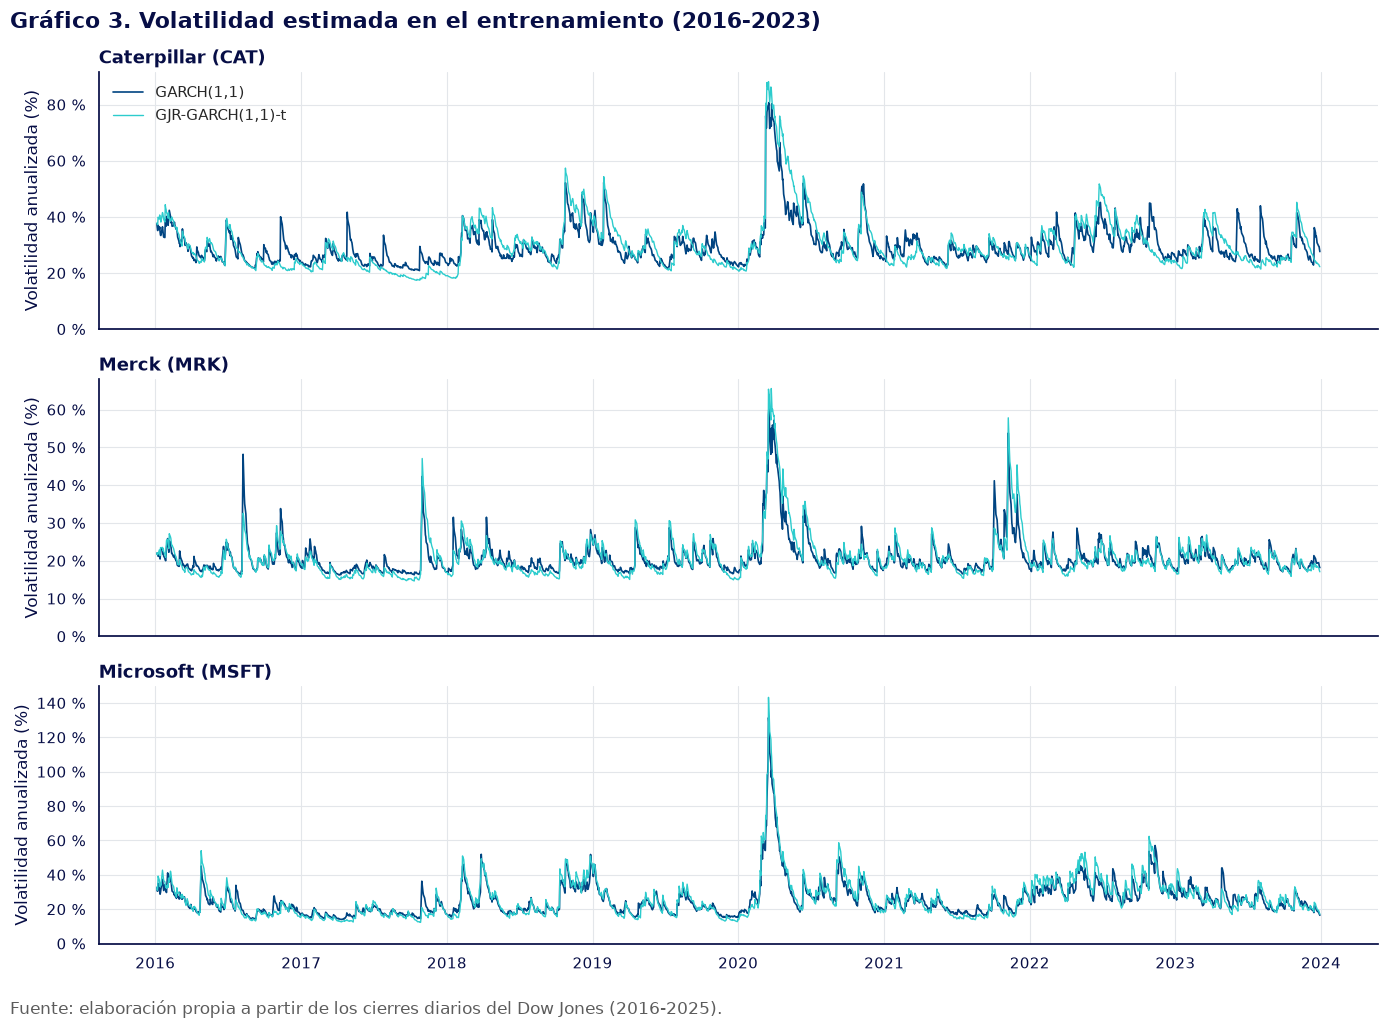

PosixPath('Graficos/volatilidad_03_modelos_entrenamiento.png')

In [8]:
fig, ejes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, t in zip(ejes, ACTIVOS):
    for nombre, color, grosor in [("GARCH(1,1)", PRINCIPAL, 1.2), ("GJR-GARCH(1,1)-t", AGUAMARINA, 1.0)]:
        vol = ajustes[(t, nombre)].conditional_volatility.dropna() * np.sqrt(DIAS_ANIO)
        ax.plot(vol, color=color, lw=grosor, label=nombre)
    eje_porcentaje(ax)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Volatilidad anualizada (%)")
    ax.set_title(f"{ACTIVOS[t]} ({t})")
ejes[0].legend(loc="upper left")
eje_anios(ejes[-1])
fig.suptitle("Gráfico 3. Volatilidad estimada en el entrenamiento (2016-2023)", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "volatilidad_03_modelos_entrenamiento", fuente=FUENTE)

ANÁLISIS:

| BIC (menor es mejor) | ARCH(p) | GARCH(1,1) | GJR-GARCH(1,1)-t |
|---|---|---|---|
| Caterpillar | 8.198 | 8.174 | **7.930** |
| Merck | 6.746 | 6.750 | **6.447** |
| Microsoft | 7.496 | 7.442 | **7.268** |

El **GJR-GARCH(1,1)-t** es el que mejor se ajusta en los tres activos, con mucha diferencia (entre 174 y 304 puntos de BIC menos que el GARCH(1,1)). Lo explican sus dos añadidos:

- **Colas gruesas:** los grados de libertad de la t son bajos (ν entre 4,3 y 5,1; una normal sería ν infinito). Hay más días extremos de los que supone una normal.
- **Asimetría:** γ es positivo y significativo en los tres (0,082 en Caterpillar y 0,150 en Microsoft, p < 0,001; 0,075 en Merck, p = 0,018). Las caídas aumentan la volatilidad más que las subidas. En Caterpillar α = 0, así que solo las caídas la aumentan.

El ARCH(p) necesita entre 6 y 9 parámetros y se ajusta peor que el GARCH(1,1) en Caterpillar y Microsoft; en Merck quedan casi empatados. Además, su persistencia es baja (0,45-0,75): olvida los sustos mucho antes que los GARCH (0,90-0,99). En el GARCH(1,1), β es significativa en los tres (p < 0,001) y α solo en Microsoft (p = 0,005). Los tres modelos recogen el agrupamiento: el Ljung-Box de la rentabilidad estandarizada al cuadrado no es significativo en ninguno (p ≥ 0,47).

En el gráfico 3 los dos GARCH dan una volatilidad muy parecida; el GJR-GARCH-t marca picos algo mayores en las caídas, como en marzo de 2020.

## 4. Predicción en el periodo de test

Cada día del test se predice la volatilidad de las 21 sesiones siguientes y se compara con la volatilidad realizada en esas 21 sesiones, anualizada. Los modelos se reestiman cada 21 sesiones con todos los datos disponibles hasta ese día (ventana creciente). Referencias: volatilidad histórica de 1 mes, histórica de 1 año y EWMA (λ = 0,94). Errores: RMSE y MAE, en puntos de volatilidad anualizada, y sesgo (predicción − realidad).

In [9]:
#Parámetros de esta sección
HORIZONTE = 21              #Se predice la volatilidad del mes siguiente (21 sesiones)
CADA_REESTIMACION = 21      #Los modelos se reestiman cada 21 sesiones (ventana creciente)
LAMBDA_EWMA = 0.94          #Factor de decaimiento de la media móvil exponencial
EPISODIO_ABRIL = ("2025-04-02", "2025-04-09")   #Anuncio de aranceles de abril de 2025

# Orígenes: del último día de entrenamiento hasta 21 sesiones antes del final (para poder medir el mes siguiente)
posiciones = np.arange(N_TRAIN - 1, len(rent) - HORIZONTE)
origenes = rent.index[posiciones]
anualizar = np.sqrt(DIAS_ANIO)


def prediccion_reestimada(serie, kw):
    pred = np.empty(len(posiciones))
    for inicio in range(0, len(posiciones), CADA_REESTIMACION):
        k = posiciones[inicio]
        res = arch_model(serie, mean="Constant", **kw).fit(last_obs=k + 1, disp="off")
        varianzas = res.forecast(horizon=HORIZONTE, start=k, reindex=False).variance.to_numpy()
        bloque = varianzas[:min(CADA_REESTIMACION, len(posiciones) - inicio)]
        pred[inicio:inicio + len(bloque)] = np.sqrt(bloque.mean(axis=1)) * anualizar
    return pred


evaluacion = {}
for t in ACTIVOS:
    r = rent[t]
    tabla = pd.DataFrame(index=origenes)
    tabla["realizada"] = [r.iloc[i + 1: i + 1 + HORIZONTE].std(ddof=0) * anualizar for i in posiciones]
    for nombre, kw in especificaciones(t).items():
        tabla[nombre] = prediccion_reestimada(r, kw)
    e2 = (r - r.iloc[:N_TRAIN].mean()) ** 2
    tabla["EWMA"] = np.sqrt(e2.ewm(alpha=1 - LAMBDA_EWMA, adjust=False).mean().iloc[posiciones].to_numpy()) * anualizar
    tabla["Histórica 1 mes"] = [r.iloc[i - HORIZONTE + 1: i + 1].std(ddof=0) * anualizar for i in posiciones]
    tabla["Histórica 1 año"] = [r.iloc[i - DIAS_ANIO + 1: i + 1].std(ddof=0) * anualizar for i in posiciones]
    evaluacion[t] = tabla

print(f"Orígenes de predicción: {len(origenes)} ({origenes[0].date()} a {origenes[-1].date()})")
print("\nPrimeras filas de CAT (volatilidad anualizada, %):")
print(evaluacion["CAT"].head().round(2).to_string())

Orígenes de predicción: 482 (2023-12-29 a 2025-12-01)

Primeras filas de CAT (volatilidad anualizada, %):
            realizada  ARCH(4)  GARCH(1,1)  GJR-GARCH(1,1)-t   EWMA  Histórica 1 mes  Histórica 1 año
date                                                                                                 
2023-12-29      22.88    29.91       28.32             23.54  26.57            24.71            28.41
2024-01-02      23.86    29.94       28.12             23.76  26.10            25.45            28.42
2024-01-03      22.11    31.40       29.49             26.71  27.84            27.56            28.58
2024-01-04      22.68    30.90       28.95             26.33  27.08            27.19            28.58
2024-01-05      22.63    30.47       28.58             25.97  26.49            27.19            28.58


In [10]:
anio_origen = origenes.year
filas = []
for t in ACTIVOS:
    ev = evaluacion[t]
    for metodo in ev.columns.drop("realizada"):
        error = ev[metodo] - ev["realizada"]
        fila = {"activo": t, "metodo": metodo,
                "RMSE": float(np.sqrt(np.mean(error ** 2))), "MAE": float(np.mean(np.abs(error))),
                "sesgo": float(error.mean())}
        for anio in (2024, 2025):
            fila[f"RMSE_{anio}"] = float(np.sqrt(np.mean(error[anio_origen == anio] ** 2)))
        filas.append(fila)
errores = pd.DataFrame(filas)
errores["mejor_RMSE"] = errores.groupby("activo")["RMSE"].transform("min") == errores["RMSE"]

for t in ACTIVOS:
    realizada = evaluacion[t]["realizada"]
    print(f"{ACTIVOS[t]} ({t}) | volatilidad realizada media: 2024 = {fmt_es(realizada[anio_origen == 2024].mean(), 1)} %, "
          f"2025 = {fmt_es(realizada[anio_origen == 2025].mean(), 1)} %")
print()
print(errores.round(2).to_string(index=False))
errores.round(4).to_csv(RUTA_RESULTADOS / "volatilidad_errores.csv", index=False, encoding="utf-8-sig")
print(f"\nGuardado: {RUTA_RESULTADOS / 'volatilidad_errores.csv'}")

Caterpillar (CAT) | volatilidad realizada media: 2024 = 24,8 %, 2025 = 29,1 %
Merck (MRK) | volatilidad realizada media: 2024 = 19,7 %, 2025 = 29,6 %
Microsoft (MSFT) | volatilidad realizada media: 2024 = 19,7 %, 2025 = 21,7 %

activo           metodo  RMSE   MAE  sesgo  RMSE_2024  RMSE_2025  mejor_RMSE
   CAT          ARCH(4) 10.20  8.50   3.68       8.97      11.42       False
   CAT       GARCH(1,1) 10.30  8.41   2.64       8.61      11.90       False
   CAT GJR-GARCH(1,1)-t 10.84  8.51   1.52       9.00      12.58       False
   CAT             EWMA 12.43  9.67   0.91       9.59      14.96       False
   CAT  Histórica 1 mes 13.54 10.54  -0.17      10.93      15.94       False
   CAT  Histórica 1 año  9.92  7.84   1.12       7.46      12.07        True
   MRK          ARCH(6)  8.90  6.88  -2.04       7.30      10.39       False
   MRK       GARCH(1,1)  8.96  6.90  -2.22       7.25      10.55       False
   MRK GJR-GARCH(1,1)-t  9.34  7.03  -0.89       8.42      10.27       False
  

Guardado: Graficos/volatilidad_04_prediccion_test.png


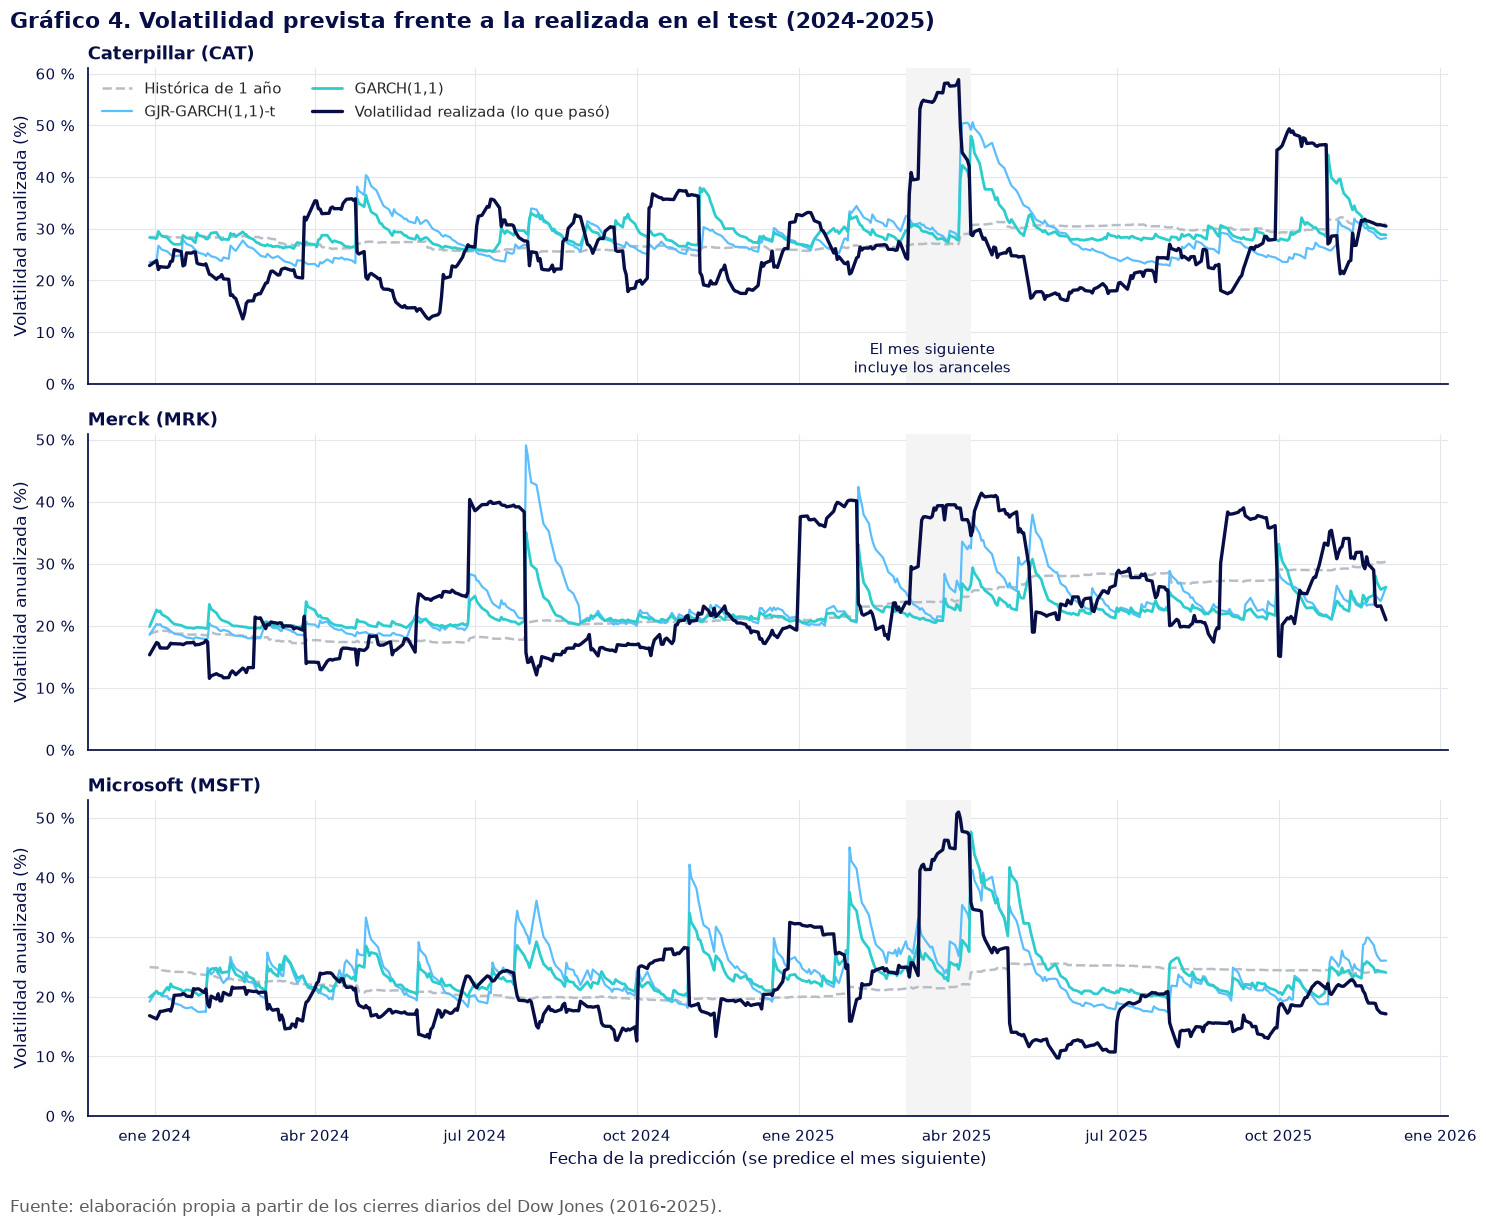

PosixPath('Graficos/volatilidad_04_prediccion_test.png')

In [11]:
#Se dibujan la realidad, el GARCH(1,1), el GJR-GARCH(1,1)-t y la referencia que mejor funciona (histórica de 1 año)
estilos = {"realizada": (MARINO, "-", 2.4, "Volatilidad realizada (lo que pasó)"),
           "GARCH(1,1)": (AGUAMARINA, "-", 2.0, "GARCH(1,1)"),
           "GJR-GARCH(1,1)-t": (CIELO, "-", 1.6, "GJR-GARCH(1,1)-t"),
           "Histórica 1 año": (GRIS, "--", 1.8, "Histórica de 1 año")}
fig, ejes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
for ax, t in zip(ejes, ACTIVOS):
    ev = evaluacion[t]
    ax.axvspan(pd.Timestamp(EPISODIO_ABRIL[0]) - pd.Timedelta(days=30), pd.Timestamp(EPISODIO_ABRIL[1]),
               color=GRIS_FONDO, lw=0)
    for columna in ["Histórica 1 año", "GJR-GARCH(1,1)-t", "GARCH(1,1)", "realizada"]:
        color, estilo, grosor, etiqueta = estilos[columna]
        ax.plot(ev[columna], color=color, ls=estilo, lw=grosor, label=etiqueta)
    eje_porcentaje(ax)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Volatilidad anualizada (%)")
    ax.set_title(f"{ACTIVOS[t]} ({t})")
ejes[0].legend(loc="upper left", ncol=2)
ejes[0].text(pd.Timestamp(EPISODIO_ABRIL[0]) - pd.Timedelta(days=15), 0.02, "El mes siguiente\nincluye los aranceles",
             transform=ejes[0].get_xaxis_transform(), ha="center", va="bottom", color=MARINO, fontsize=11)
ejes[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ejes[-1].xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"][mdates.num2date(x).month - 1]
    + f" {mdates.num2date(x).year}"))
ejes[-1].set_xlabel("Fecha de la predicción (se predice el mes siguiente)")
fig.suptitle("Gráfico 4. Volatilidad prevista frente a la realizada en el test (2024-2025)", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "volatilidad_04_prediccion_test", fuente=FUENTE)

ANÁLISIS:

Los tres modelos reaccionan en cuanto llega un susto y luego se calman poco a poco; el GJR-GARCH-t sube más y tarda más en bajar (por ejemplo, Merck en agosto de 2024). Ningún método anticipa los sustos: en marzo de 2025 la volatilidad del mes siguiente se dispara por los aranceles (zona sombreada) y todas las predicciones siguen tranquilas. La histórica de 1 año apenas se mueve.

El comportamiento cambia entre los dos años. 2024 fue tranquilo (volatilidad realizada media del 24,8 %, 19,7 % y 19,7 %) y los modelos sobrestiman el riesgo después de cada pequeño susto, sobre todo en Microsoft. En 2025, más agitado (29,1 %, 29,6 % y 21,7 %), los modelos siguen mejor los cambios de volatilidad.

Guardado: Graficos/volatilidad_05_rmse.png


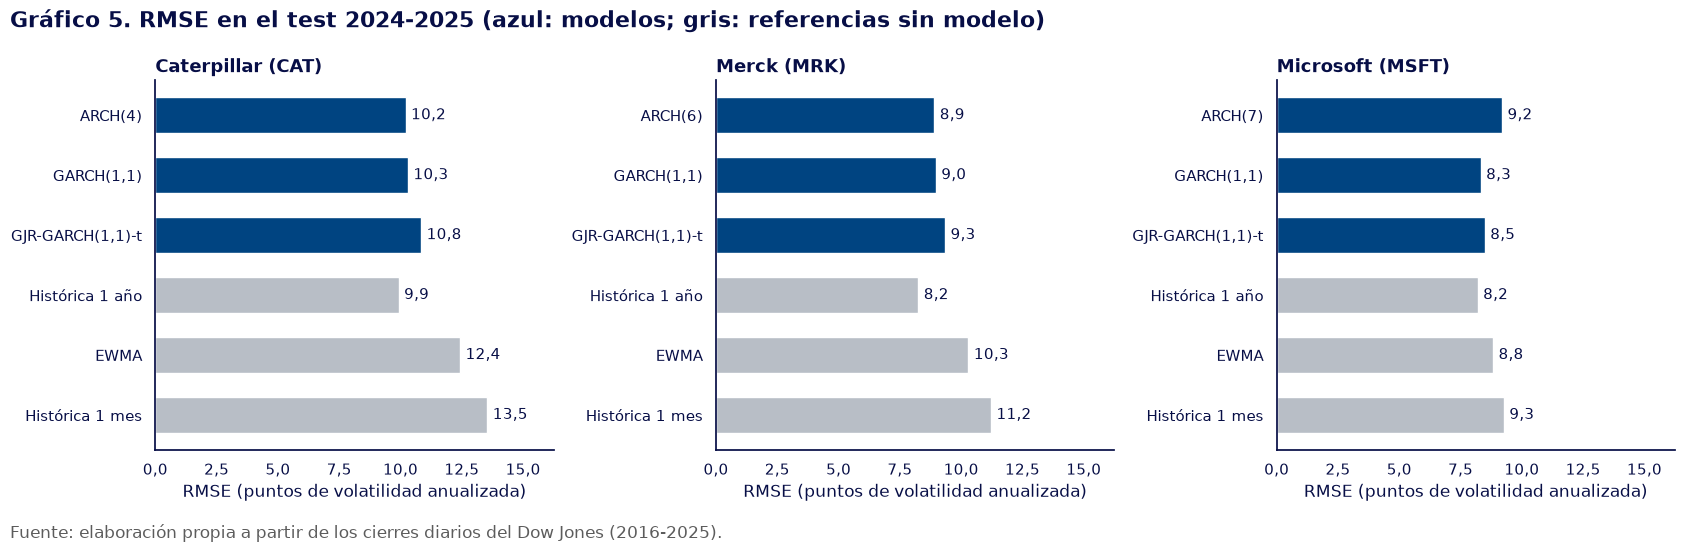

PosixPath('Graficos/volatilidad_05_rmse.png')

In [12]:
orden = ["Histórica 1 mes", "EWMA", "Histórica 1 año"]
fig, ejes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True)
for ax, t in zip(ejes, ACTIVOS):
    datos = errores[errores["activo"] == t].set_index("metodo")
    modelos = [m for m in datos.index if m not in orden]
    datos = datos.loc[orden + modelos[::-1]]
    colores = [PRINCIPAL if m in modelos else GRIS for m in datos.index]
    barras = ax.barh(datos.index, datos["RMSE"], color=colores, height=0.6)
    ax.bar_label(barras, labels=[fmt_es(v, 1) for v in datos["RMSE"]], padding=4, color=MARINO, fontsize=11)
    ax.set_xlim(0, errores["RMSE"].max() * 1.2)
    ax.grid(False)
    ax.set_xlabel("RMSE (puntos de volatilidad anualizada)")
    ax.set_title(f"{ACTIVOS[t]} ({t})")
fig.suptitle("Gráfico 5. RMSE en el test 2024-2025 (azul: modelos; gris: referencias sin modelo)", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "volatilidad_05_rmse", fuente=FUENTE)

ANÁLISIS:

| RMSE (puntos) | Caterpillar | | | Merck | | | Microsoft | | |
|---|---|---|---|---|---|---|---|---|---|
| | **Total** | 2024 | 2025 | **Total** | 2024 | 2025 | **Total** | 2024 | 2025 |
| ARCH(p) | 10,2 | 9,0 | **11,4** | 8,9 | 7,3 | 10,4 | 9,2 | 7,7 | 10,6 |
| GARCH(1,1) | 10,3 | 8,6 | 11,9 | 9,0 | **7,2** | 10,6 | 8,3 | 6,0 | 10,3 |
| GJR-GARCH(1,1)-t | 10,8 | 9,0 | 12,6 | 9,3 | 8,4 | 10,3 | 8,5 | 7,5 | **9,4** |
| Histórica 1 año | **9,9** | **7,5** | 12,1 | **8,2** | 7,3 | **9,2** | **8,2** | **4,3** | 11,0 |
| EWMA | 12,4 | 9,6 | 15,0 | 10,3 | 9,1 | 11,5 | 8,8 | 5,5 | 11,4 |
| Histórica 1 mes | 13,5 | 10,9 | 15,9 | 11,2 | 9,3 | 13,1 | 9,3 | 6,2 | 11,8 |

- **Los modelos mejoran mucho a las referencias de corto plazo:** el GARCH(1,1) tiene entre un 10 % y un 24 % menos de error que la histórica de 1 mes en los tres activos, y también menos que la EWMA.
- **En el conjunto de los dos años, la histórica de 1 año tiene el menor RMSE y el menor MAE en los tres activos**, aunque por poco frente al mejor modelo (0,1-0,7 puntos de RMSE). En Caterpillar y Microsoft su ventaja viene de 2024: en un año tranquilo, una predicción estable acierta más que un modelo que reacciona a cada susto.
- **En 2025, con estrés, ganan los modelos** en Caterpillar (ARCH(4): 11,4 frente a 12,1) y en Microsoft (GJR-GARCH-t: 9,4 frente a 11,0). En Merck sigue ganando la histórica de 1 año, porque su volatilidad subió de forma duradera y no por sustos puntuales.
- **Mejor ajuste no es mejor predicción:** el GJR-GARCH-t tiene el mejor BIC, pero en el conjunto del test predice algo peor que el GARCH(1,1) en los tres activos. Sus parámetros extra describen mejor los días extremos del pasado, pero no mejoran la predicción de la volatilidad media del mes siguiente.
- **Sesgo:** los modelos sobrestiman el riesgo en Caterpillar y Microsoft (el GARCH(1,1) en +2,7 y +3,4 puntos) y lo infravaloran en Merck (−2,2).

## 5. Conclusión y limitaciones

De los modelos del tema, el más conveniente para predecir la volatilidad de la cartera es el **GARCH(1,1)**. Con solo 4 parámetros predice tan bien como el ARCH(p), que necesita entre 6 y 9, y mejor que el GJR-GARCH(1,1)-t, a pesar de que este último es el que mejor se ajusta a los datos (menor BIC). El GJR-GARCH-t es útil para describir el riesgo: confirma que las caídas aumentan la volatilidad más que las subidas y que hay más días extremos de los que supone una normal.

Ningún modelo supera de forma clara a la volatilidad histórica de 1 año en el conjunto de 2024-2025. Los modelos aportan valor en los periodos de estrés, como 2025, porque reaccionan rápido a los sustos; en periodos tranquilos, una predicción estable funciona igual o mejor. Para la cartera, lo razonable es usar el GARCH(1,1) para seguir el riesgo en el día a día y la volatilidad de 1 año como referencia estable.

**Limitaciones:**
- Dos años de test con predicciones solapadas: diferencias de menos de 1 punto de RMSE pueden no ser significativas.
- La volatilidad realizada se mide con solo 21 rentabilidades, así que también tiene ruido.
- Ningún modelo basado en precios pasados puede anticipar noticias como los aranceles de abril de 2025.